In [5]:
import sys

import joblib
import numpy as np
import pandas as pd
import sklearn

print(f"Python: {sys.version}")
print(f"NumPy: {np.__version__}")
print(f"pandas: {pd.__version__}")
print(f"scikit-learn: {sklearn.__version__}")
print(f"joblib: {joblib.__version__}")

Python: 3.12.0 (tags/v3.12.0:0fb18b0, Oct  2 2023, 13:03:39) [MSC v.1935 64 bit (AMD64)]
NumPy: 2.3.4
pandas: 2.3.3
scikit-learn: 1.7.2
joblib: 1.5.2


In [6]:
SEED = 2729

train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")

print(f"Train shape: {train.shape}")
print(f"Test shape:  {test.shape}")
print(f"Train columns: {train.columns.tolist()}")
print(f"Test columns:  {test.columns.tolist()}")
print(f"Columns present in train but missing from test: {train.columns.difference(test.columns).tolist()}")
print(f"Share of 'yes' in train: {(train['y'] == 'yes').mean():.4f}")
print(f"Duplicate train id values: {train['id'].duplicated().sum()}")
print(f"Duplicate test id values:  {test['id'].duplicated().sum()}")

Train shape: (32940, 22)
Test shape:  (8236, 20)
Train columns: ['id', 'age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']
Test columns:  ['id', 'age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Columns present in train but missing from test: ['duration', 'y']
Share of 'yes' in train: 0.1127
Duplicate train id values: 0
Duplicate test id values:  0


In [7]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score

y_train = train["y"].eq("yes").astype(int)
dummy_X = np.zeros((len(y_train), 1))

always_no_predictions = np.zeros(len(y_train), dtype=int)
prior_model = DummyClassifier(strategy="prior", random_state=SEED)
prior_model.fit(dummy_X, y_train)
prior_predictions = prior_model.predict(dummy_X)

baseline_results = pd.DataFrame(
    [
        {
            "baseline": "Always no",
            "accuracy": accuracy_score(y_train, always_no_predictions),
            "f1": f1_score(y_train, always_no_predictions, zero_division=0),
        },
        {
            "baseline": "DummyClassifier (prior)",
            "accuracy": accuracy_score(y_train, prior_predictions),
            "f1": f1_score(y_train, prior_predictions, zero_division=0),
        },
    ]
).set_index("baseline")
display(baseline_results.round(3))

always_no = baseline_results.loc["Always no"]
if always_no["accuracy"] > 0.8 and always_no["f1"] == 0:
    print("Conclusion: always predicting 'no' gives high accuracy but misses every 'yes' (F1 = 0).")
else:
    print("Conclusion: compare F1 as well as accuracy; accuracy alone does not show performance on 'yes'.")

,accuracy,f1
baseline,,
Always no,0.887,0.0
DummyClassifier (prior),0.887,0.0


Conclusion: always predicting 'no' gives high accuracy but misses every 'yes' (F1 = 0).


In [8]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer

from feature_transformers import add_was_contacted

feature_cols = [column for column in train.columns if column not in {"id", "duration", "y"}]
train_features = train.loc[:, feature_cols]

numeric_type_cols = [
    column
    for column in train_features.select_dtypes(include=np.number).columns
    if column != "pdays"
]
categorical_cols = train_features.select_dtypes(exclude=np.number).columns.tolist() + ["pdays"]
type_summary = pd.DataFrame(
    {
        "feature_count": [len(numeric_type_cols), len(categorical_cols)],
        "columns": [", ".join(numeric_type_cols), ", ".join(categorical_cols)],
    },
    index=["Numeric", "Categorical"],
)
display(type_summary)

unknown_counts = train_features.eq("unknown").sum()
display(unknown_counts[unknown_counts.gt(0)].rename("unknown_count").to_frame())
print(f"Share of pdays == 999: {train_features['pdays'].eq(999).mean():.4f}")

# Treat pdays as a category so its 999 sentinel is not interpreted as a numeric value.
numeric_cols = numeric_type_cols + ["was_contacted"]
print(f"numeric_cols: {numeric_cols}")
print(f"categorical_cols: {categorical_cols}")

feature_engineering = Pipeline(
    [
        (
            "add_was_contacted",
            FunctionTransformer(add_was_contacted, validate=False),
        )
    ]
)

,feature_count,columns
Numeric,8,"age, campaign, previous, emp.var.rate, cons.pr..."
Categorical,11,"job, marital, education, default, housing, loa..."


,unknown_count
job,275
marital,64
education,1401
default,6871
housing,794
loan,794


Share of pdays == 999: 0.9622
numeric_cols: ['age', 'campaign', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'was_contacted']
categorical_cols: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome', 'pdays']


In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import make_scorer
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from feature_transformers import precision_at_fraction

numeric_preprocessing = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)
categorical_preprocessing = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]
)

preprocessor = ColumnTransformer(
    [
        ("numeric", numeric_preprocessing, numeric_cols),
        ("categorical", categorical_preprocessing, categorical_cols),
    ]
)

logistic_pipeline = Pipeline(
    [
        ("feature_engineering", feature_engineering),
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=5000,
                class_weight="balanced",
                random_state=SEED,
            ),
        ),
    ]
)

X_dev, X_holdout, y_dev, y_holdout = train_test_split(
    train_features,
    y_train,
    test_size=0.2,
    stratify=y_train,
    random_state=SEED,
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {
    "precision_at_10_percent": make_scorer(
        precision_at_fraction,
        response_method="predict_proba",
        fraction=0.1,
    ),
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
}
cv_results = cross_validate(
    logistic_pipeline,
    X_dev,
    y_dev,
    cv=cv,
    scoring=scoring,
    return_train_score=False,
    n_jobs=-1,
)

cv_summary = pd.DataFrame(
    {
        "metric": ["Precision@10% (primary)", "ROC AUC", "Average precision (PR AUC)"],
        "mean": [
            cv_results["test_precision_at_10_percent"].mean(),
            cv_results["test_roc_auc"].mean(),
            cv_results["test_average_precision"].mean(),
        ],
        "std": [
            cv_results["test_precision_at_10_percent"].std(ddof=1),
            cv_results["test_roc_auc"].std(ddof=1),
            cv_results["test_average_precision"].std(ddof=1),
        ],
    }
)
cv_summary["mean ± std"] = cv_summary.apply(
    lambda row: f"{row['mean']:.4f} ± {row['std']:.4f}", axis=1
)
display(cv_summary[["metric", "mean ± std"]])

,metric,mean ± std
0,Precision@10% (primary),0.4877 ± 0.0234
1,ROC AUC,0.7890 ± 0.0084
2,Average precision (PR AUC),0.4369 ± 0.0173


,value
Decision threshold (top 10%),0.7862
Precision@10% (primary),0.4882
Recall at 10% capacity,0.4335
Share selected,0.1000
OOF average precision,0.4343


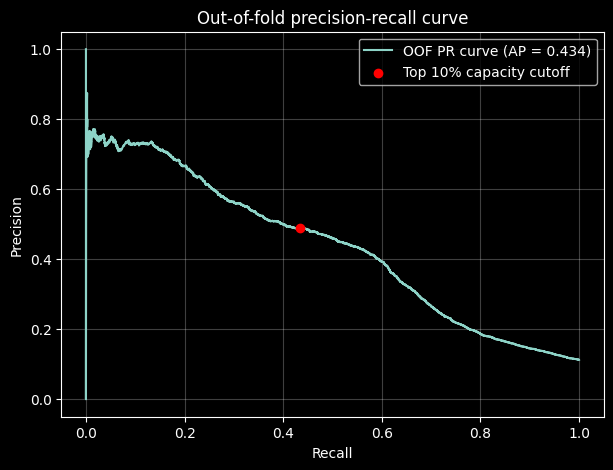

In [10]:
import matplotlib.pyplot as plt

from sklearn.metrics import average_precision_score, precision_recall_curve
from sklearn.model_selection import cross_val_predict

oof_probabilities = cross_val_predict(
    logistic_pipeline,
    X_dev,
    y_dev,
    cv=cv,
    method="predict_proba",
    n_jobs=-1,
)[:, 1]
pr_precision, pr_recall, pr_thresholds = precision_recall_curve(
    y_dev,
    oof_probabilities,
)

capacity = 0.10
n_to_call = int(np.ceil(capacity * len(y_dev)))
top_indices = np.argsort(-oof_probabilities, kind="stable")[:n_to_call]
decision_threshold = oof_probabilities[top_indices[-1]]
oof_predictions = np.zeros(len(y_dev), dtype=int)
oof_predictions[top_indices] = 1

precision_at_10 = y_dev.iloc[top_indices].mean()
recall_at_10 = precision_at_10 * n_to_call / y_dev.sum()
oof_average_precision = average_precision_score(y_dev, oof_probabilities)

threshold_results = pd.DataFrame(
    {
        "value": [
            decision_threshold,
            precision_at_10,
            recall_at_10,
            n_to_call / len(y_dev),
            oof_average_precision,
        ]
    },
    index=[
        "Decision threshold (top 10%)",
        "Precision@10% (primary)",
        "Recall at 10% capacity",
        "Share selected",
        "OOF average precision",
    ],
)
display(threshold_results.round(4))

plt.figure(figsize=(7, 5))
plt.plot(pr_recall, pr_precision, label=f"OOF PR curve (AP = {oof_average_precision:.3f})")
plt.scatter(
    [recall_at_10],
    [precision_at_10],
    color="red",
    zorder=3,
    label="Top 10% capacity cutoff",
)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Out-of-fold precision-recall curve")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

random_forest_pipeline = Pipeline(
    [
        ("feature_engineering", feature_engineering),
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                random_state=SEED,
                class_weight="balanced",
                n_jobs=-1,
            ),
        ),
    ]
)

inner_cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=SEED)
random_forest_search = GridSearchCV(
    estimator=random_forest_pipeline,
    param_grid={"classifier__n_estimators": [200], "classifier__min_samples_leaf": [2, 5]},
    scoring=scoring["precision_at_10_percent"],
    cv=inner_cv,
    refit=True,
    n_jobs=1,
)

model_candidates = {
    "Logistic regression": logistic_pipeline,
    "Random forest (tuned)": random_forest_search,
}
model_cv_results = {}
for model_name, estimator in model_candidates.items():
    model_cv_results[model_name] = cross_validate(
        estimator,
        X_dev,
        y_dev,
        cv=cv,
        scoring=scoring,
        return_train_score=False,
        n_jobs=1,
    )

comparison_rows = []
for model_name, results in model_cv_results.items():
    for metric_name, score_key in [
        ("Precision@10% (primary)", "test_precision_at_10_percent"),
        ("ROC AUC", "test_roc_auc"),
        ("Average precision", "test_average_precision"),
    ]:
        fold_scores = results[score_key]
        comparison_rows.append(
            {
                "model": model_name,
                "metric": metric_name,
                "mean ± std": f"{fold_scores.mean():.4f} ± {fold_scores.std(ddof=1):.4f}",
            }
        )

model_comparison = pd.DataFrame(comparison_rows)
display(model_comparison.pivot(index="model", columns="metric", values="mean ± std"))

print(f"Random forest search grid: {random_forest_search.param_grid}")
print("Random forest scores use nested CV: tuning is repeated inside each outer training fold.")

metric,Average precision,Precision@10% (primary),ROC AUC
model,,,
Logistic regression,0.4369 ± 0.0173,0.4877 ± 0.0234,0.7890 ± 0.0084
Random forest (tuned),0.4570 ± 0.0154,0.5040 ± 0.0192,0.7908 ± 0.0089


Random forest search grid: {'classifier__n_estimators': [200], 'classifier__min_samples_leaf': [2, 5]}
Random forest scores use nested CV: tuning is repeated inside each outer training fold.


In [ ]:
selected_oof_probabilities = cross_val_predict(
    random_forest_search,
    X_dev,
    y_dev,
    cv=cv,
    method="predict_proba",
    n_jobs=1,
)[:, 1]
selected_pr_precision, selected_pr_recall, _ = precision_recall_curve(
    y_dev,
    selected_oof_probabilities,
)

selected_n_to_call = int(np.ceil(capacity * len(y_dev)))
selected_top_indices = np.argsort(-selected_oof_probabilities, kind="stable")[:selected_n_to_call]
decision_threshold = selected_oof_probabilities[selected_top_indices[-1]]
selected_precision_at_10 = y_dev.iloc[selected_top_indices].mean()
selected_recall_at_10 = selected_precision_at_10 * selected_n_to_call / y_dev.sum()
selected_oof_average_precision = average_precision_score(y_dev, selected_oof_probabilities)

display(
    pd.DataFrame(
        {
            "value": [
                decision_threshold,
                selected_precision_at_10,
                selected_recall_at_10,
                selected_n_to_call / len(y_dev),
                selected_oof_average_precision,
            ]
        },
        index=[
            "Random forest OOF threshold (top 10%)",
            "Precision@10%",
            "Recall at 10% capacity",
            "Share selected",
            "OOF average precision",
        ],
    ).round(4)
)

plt.figure(figsize=(7, 5))
plt.plot(
    selected_pr_recall,
    selected_pr_precision,
    label=f"Random forest OOF PR curve (AP = {selected_oof_average_precision:.3f})",
)
plt.scatter(
    [selected_recall_at_10],
    [selected_precision_at_10],
    color="red",
    zorder=3,
    label="Top 10% capacity cutoff",
)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Selected model: out-of-fold precision-recall curve")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

In [ ]:
final_search = GridSearchCV(
    estimator=random_forest_pipeline,
    param_grid=random_forest_search.param_grid,
    scoring=scoring["precision_at_10_percent"],
    cv=inner_cv,
    refit=True,
    n_jobs=1,
)
final_search.fit(train_features, y_train)
final_pipeline = final_search.best_estimator_
joblib.dump(final_pipeline, "model.joblib")

print(f"Selected final parameters: {final_search.best_params_}")
print("Saved fitted pipeline to model.joblib")

In [ ]:
loaded_pipeline = joblib.load("model.joblib")
test_features = test.drop(columns="id")
in_memory_test_scores = final_pipeline.predict_proba(test_features)[:, 1]
loaded_test_scores = loaded_pipeline.predict_proba(test_features)[:, 1]

np.testing.assert_allclose(loaded_test_scores, in_memory_test_scores, rtol=1e-12, atol=1e-12)

test_predictions = (loaded_test_scores >= decision_threshold).astype(int)
predictions = pd.DataFrame(
    {
        "id": test["id"],
        "y_pred": test_predictions,
        "y_score": loaded_test_scores,
    }
)
predictions.to_csv("predictions.csv", index=False)

print(f"Reloaded predictions match in-memory predictions: {np.allclose(loaded_test_scores, in_memory_test_scores, rtol=1e-12, atol=1e-12)}")
print(f"Predictions shape: {predictions.shape}")
print(f"Prediction columns: {predictions.columns.tolist()}")
print(f"Share predicted yes: {predictions['y_pred'].mean():.4f}")